In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q ultralytics opencv-python pillow psutil pandas matplotlib
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
MODEL_DIR = BASE_DIR + "models/E1/"
BENCHMARK_DIR = BASE_DIR + "benchmarks/"

In [ ]:
import os
import re
import time
import json
import platform
import psutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
from mobile_sam import (
    sam_model_registry,
    SamAutomaticMaskGenerator,
    SamPredictor
)

/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_5m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_11m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_11m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_21m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_21m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_

In [ ]:
DEVICE = "cpu"

CPU_THREADS = max(
    1,
    os.cpu_count() // 2
)

cv2.setNumThreads(CPU_THREADS)

print("CPU:", platform.processor())
print("Logical CPU cores:", os.cpu_count())
print("OpenCV threads:", CPU_THREADS)
print("RAM:",
      round(
          psutil.virtual_memory().total / (1024**3),
          2
      ),
      "GB")

CPU: x86_64
Logical CPU cores: 2
OpenCV threads: 1
RAM: 12.67 GB


In [ ]:
YOLO_MODEL_NAME = "yolov8n.pt"

yolo_model = YOLO(
    YOLO_MODEL_NAME
)

print("YOLOv8n loaded.")

YOLOv8n loaded.


In [ ]:
MOBILE_SAM_PATH = "mobile_sam.pt"

if not os.path.exists(MOBILE_SAM_PATH):

    !wget -q \
        https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt \
        -O mobile_sam.pt

print(
    "MobileSAM checkpoint size:",
    round(
        os.path.getsize(MOBILE_SAM_PATH) / (1024**2),
        2
    ),
    "MB"
)

MobileSAM checkpoint size: 38.84 MB


In [ ]:
mobile_sam = sam_model_registry[
    "vit_t"
](
    checkpoint=MOBILE_SAM_PATH
)

mobile_sam.to(
    device=DEVICE
)

mobile_sam.eval()

predictor = SamPredictor(
    mobile_sam
)

print("MobileSAM loaded on CPU.")

MobileSAM loaded on CPU.


In [ ]:
mobile_sam_size_mb = (
    os.path.getsize(MOBILE_SAM_PATH)
    / (1024 ** 2)
)

mobile_sam_params = sum(
    p.numel()
    for p in mobile_sam.parameters()
)

print(
    f"MobileSAM size: "
    f"{mobile_sam_size_mb:.2f} MB"
)

print(
    f"MobileSAM parameters: "
    f"{mobile_sam_params:,}"
)

print(
    f"MobileSAM parameters: "
    f"{mobile_sam_params / 1e6:.2f} M"
)

MobileSAM size: 38.84 MB
MobileSAM parameters: 10,130,092
MobileSAM parameters: 10.13 M


In [ ]:
def normalize_target(target):

    words_to_remove = {
        "red", "blue", "green",
        "yellow", "black", "white",
        "small", "large",
        "big", "little",
        "the", "a", "an"
    }

    words = target.lower().split()

    remaining = [
        word
        for word in words
        if word not in words_to_remove
    ]

    return " ".join(remaining)

In [ ]:
def find_class_id(target):

    target = normalize_target(
        target
    )

    for class_id, class_name in yolo_model.names.items():

        if class_name.lower() == target:
            return class_id

    return None

In [ ]:
def detect_target_e1(
    image,
    target,
    confidence=0.25,
    imgsz=640
):

    class_id = find_class_id(
        target
    )

    if class_id is None:
        raise ValueError(
            f"'{target}' is not available "
            "in YOLOv8 COCO classes."
        )

    results = yolo_model.predict(
        source=image,
        device=DEVICE,
        conf=confidence,
        imgsz=imgsz,
        verbose=False
    )

    result = results[0]

    detections = []

    if result.boxes is None:
        return detections

    for box in result.boxes:

        detected_class = int(
            box.cls.item()
        )

        if detected_class != class_id:
            continue

        xyxy = (
            box.xyxy[0]
            .cpu()
            .numpy()
            .astype(int)
        )

        detections.append({
            "bbox": xyxy,
            "confidence":
                float(box.conf.item()),
            "class":
                yolo_model.names[
                    detected_class
                ]
        })

    return detections

In [ ]:
def segment_bbox_with_mobile_sam(
    image,
    bbox
):

    # Convert BGR → RGB
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    # Set image for MobileSAM
    predictor.set_image(
        image_rgb
    )

    # SAM expects XYXY box
    input_box = np.array(
        bbox,
        dtype=np.float32
    )

    # Predict mask from bounding-box prompt
    masks, scores, logits = predictor.predict(
        box=input_box,
        multimask_output=True
    )

    # Select highest-confidence mask
    best_idx = np.argmax(scores)

    best_mask = masks[
        best_idx
    ]

    best_score = float(
        scores[best_idx]
    )

    # Convert bool → uint8
    mask = (
        best_mask.astype(np.uint8)
        * 255
    )

    return mask, best_score

In [ ]:
IMG_PATH = BASE_DIR
image = cv2.imread(
    IMG_PATH + "car_2.jpg"
)

detections = detect_target_e1(
    image,
    "car"
)

if len(detections) == 0:
    raise RuntimeError(
        "Car was not detected."
    )

best_detection = max(
    detections,
    key=lambda x: x["confidence"]
)

bbox = best_detection["bbox"]

# E0 mask
e0_mask = np.zeros(
    image.shape[:2],
    dtype=np.uint8
)

x1, y1, x2, y2 = bbox

e0_mask[
    y1:y2,
    x1:x2
] = 255

# E1 mask
e1_mask, sam_score = (
    segment_bbox_with_mobile_sam(
        image,
        bbox
    )
)

print(
    "YOLO confidence:",
    best_detection["confidence"]
)

print(
    "MobileSAM score:",
    sam_score
)

YOLO confidence: 0.9326183199882507
MobileSAM score: 0.9966510534286499


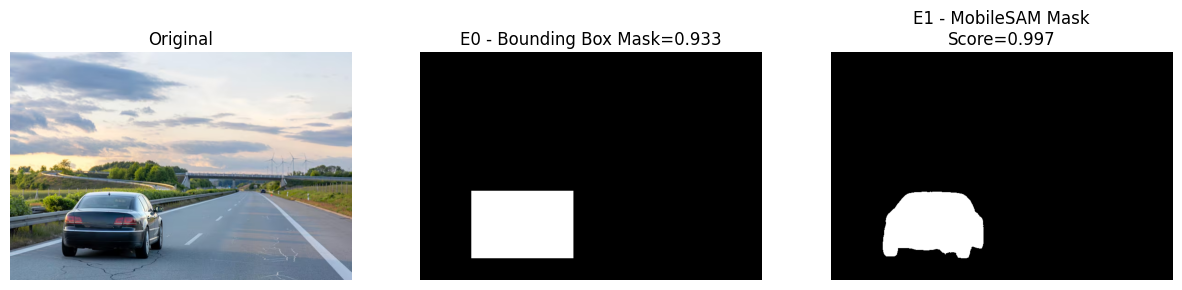

In [ ]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    e0_mask,
    cmap="gray"
)

plt.title(f"E0 - Bounding Box Mask={best_detection["confidence"]:.3f}")
plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    e1_mask,
    cmap="gray"
)

plt.title(
    f"E1 - MobileSAM Mask\nScore={sam_score:.3f}"
)

plt.axis("off")

plt.show()

In [ ]:
def clean_segmentation_mask(
    mask,
    kernel_size=3
):

    kernel = np.ones(
        (kernel_size, kernel_size),
        np.uint8
    )

    cleaned = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    cleaned = cv2.morphologyEx(
        cleaned,
        cv2.MORPH_OPEN,
        kernel
    )

    return cleaned

In [ ]:
e1_mask = clean_segmentation_mask(
    e1_mask
)

In [ ]:
def parse_instruction(instruction):
    """
    Parse simple natural-language editing instructions.

    Returns:
        {
            "operation": "remove" or "replace",
            "target": str,
            "replacement": str or None
        }
    """

    text = instruction.lower().strip()

    # Replacement patterns
    replacement_patterns = [
        r"(?:replace|change|turn)\s+(?:the\s+)?(.+?)\s+(?:with|to|into)\s+(?:a\s+|an\s+|the\s+)?(.+)",
    ]

    for pattern in replacement_patterns:
        match = re.search(pattern, text)

        if match:
            target = match.group(1).strip()
            replacement = match.group(2).strip()

            return {
                "operation": "replace",
                "target": target,
                "replacement": replacement
            }

    # Removal patterns
    removal_patterns = [
        r"(?:remove|delete|erase)\s+(?:the\s+)?(.+)",
    ]

    for pattern in removal_patterns:
        match = re.search(pattern, text)

        if match:
            target = match.group(1).strip()

            return {
                "operation": "remove",
                "target": target,
                "replacement": None
            }

    raise ValueError(
        "Could not parse instruction. "
        "Use formats such as 'remove the car' or "
        "'replace the car with a bicycle'."
    )

In [ ]:
def e1_remove(
    image,
    instruction,
    confidence=0.25,
    imgsz=640
):

    start = time.perf_counter()

    # --------------------------------
    # Parse instruction
    # --------------------------------
    parsed = parse_instruction(
        instruction
    )

    if parsed["operation"] != "remove":
        raise ValueError(
            "Expected removal instruction."
        )

    target = parsed["target"]

    # --------------------------------
    # YOLO detection
    # --------------------------------
    detection_start = (
        time.perf_counter()
    )

    detections = detect_target_e1(
        image,
        target,
        confidence=confidence,
        imgsz=imgsz
    )

    detection_time = (
        time.perf_counter()
        - detection_start
    )

    if len(detections) == 0:
        raise RuntimeError(
            f"Could not detect target: {target}"
        )

    best_detection = max(
        detections,
        key=lambda x: x["confidence"]
    )

    bbox = best_detection["bbox"]

    # --------------------------------
    # MobileSAM segmentation
    # --------------------------------
    segmentation_start = (
        time.perf_counter()
    )

    mask, sam_score = (
        segment_bbox_with_mobile_sam(
            image,
            bbox
        )
    )

    mask = clean_segmentation_mask(
        mask
    )

    segmentation_time = (
        time.perf_counter()
        - segmentation_start
    )

    # --------------------------------
    # Inpainting
    # --------------------------------
    inpainting_start = (
        time.perf_counter()
    )

    output = cv2.inpaint(
        image,
        mask,
        5,
        cv2.INPAINT_TELEA
    )

    inpainting_time = (
        time.perf_counter()
        - inpainting_start
    )

    total_time = (
        time.perf_counter()
        - start
    )

    metadata = {

        "instruction":
            instruction,

        "operation":
            "remove",

        "target":
            target,

        "bbox":
            bbox.tolist(),

        "yolo_confidence":
            best_detection["confidence"],

        "mobile_sam_score":
            sam_score,

        "detection_time_sec":
            detection_time,

        "segmentation_time_sec":
            segmentation_time,

        "inpainting_time_sec":
            inpainting_time,

        "total_time_sec":
            total_time
    }

    return (
        output,
        mask,
        metadata
    )

In [ ]:
image = cv2.imread(
    BASE_DIR + "car.jpg"
)

output, mask, metadata = e1_remove(
    image,
    "Remove the car"
)

print(
    json.dumps(
        metadata,
        indent=2
    )
)

{
  "instruction": "Remove the car",
  "operation": "remove",
  "target": "car",
  "bbox": [
    267,
    267,
    429,
    381
  ],
  "yolo_confidence": 0.9229576587677002,
  "mobile_sam_score": 0.9894143342971802,
  "detection_time_sec": 0.1591852659998949,
  "segmentation_time_sec": 3.7317678680001336,
  "inpainting_time_sec": 0.05380449199992654,
  "total_time_sec": 3.9448067739999715
}


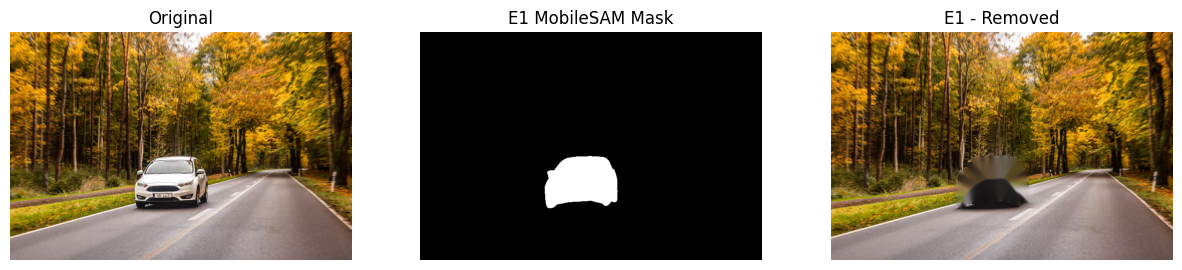

In [ ]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    mask,
    cmap="gray"
)

plt.title("E1 MobileSAM Mask")
plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("E1 - Removed")
plt.axis("off")

plt.show()

In [ ]:
import os
REFERENCE_DIR = BASE_DIR + "assets/"

def get_reference_path(replacement):
    """
    Automatically find the reference image corresponding
    to the replacement object.

    Example:
        bicycle -> assets/bicycle.png
        dog     -> assets/dog.png
    """

    replacement = replacement.lower().strip()

    # Remove common articles
    replacement = replacement.replace("a ", "")
    replacement = replacement.replace("an ", "")
    replacement = replacement.replace("the ", "")

    # Normalize spaces
    replacement = replacement.strip()

    # Direct path
    reference_path = os.path.join(
        REFERENCE_DIR,
        f"{replacement}.png"
    )

    if os.path.exists(reference_path):
        return reference_path

    # Try jpg/jpeg as fallback
    for ext in [".jpg", ".jpeg", ".webp"]:
        path = os.path.join(
            REFERENCE_DIR,
            replacement + ext
        )

        if os.path.exists(path):
            return path

    raise FileNotFoundError(
        f"No reference image found for "
        f"'{replacement}'. Expected something like: "
        f"{REFERENCE_DIR}/{replacement}.png"
    )

In [ ]:
def load_rgba_image(path):
    """
    Load an image preserving alpha channel.
    """
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)

    if img is None:
        raise FileNotFoundError(path)

    # If image has no alpha channel
    if img.shape[2] == 3:
        alpha = np.ones(
            img.shape[:2],
            dtype=np.uint8
        ) * 255

        img = np.dstack([img, alpha])

    return img

In [ ]:
def resize_reference_to_bbox(
    reference,
    bbox,
    scale=0.85
):
    x1, y1, x2, y2 = bbox

    target_width = x2 - x1
    target_height = y2 - y1

    target_width = max(
        1,
        int(target_width * scale)
    )

    target_height = max(
        1,
        int(target_height * scale)
    )

    resized = cv2.resize(
        reference,
        (target_width, target_height),
        interpolation=cv2.INTER_AREA
    )

    return resized

In [ ]:
def alpha_blend(
    background,
    foreground,
    x,
    y
):
    """
    Alpha-composite RGBA foreground
    onto BGR background.
    """

    h, w = foreground.shape[:2]

    H, W = background.shape[:2]

    # Clip coordinates
    x1 = max(0, x)
    y1 = max(0, y)

    x2 = min(W, x + w)
    y2 = min(H, y + h)

    if x1 >= x2 or y1 >= y2:
        return background

    fg = foreground[
        y1-y:y2-y,
        x1-x:x2-x
    ]

    bg = background[
        y1:y2,
        x1:x2
    ]

    alpha = fg[:, :, 3:4].astype(
        np.float32
    ) / 255.0

    fg_rgb = fg[:, :, :3].astype(
        np.float32
    )

    bg_rgb = bg.astype(
        np.float32
    )

    blended = (
        alpha * fg_rgb +
        (1 - alpha) * bg_rgb
    )

    background[
        y1:y2,
        x1:x2
    ] = blended.astype(np.uint8)

    return background

In [ ]:
def place_reference_object(
    image,
    bbox,
    reference_path,
    scale=0.85
):
    reference = load_rgba_image(
        reference_path
    )

    reference = resize_reference_to_bbox(
        reference,
        bbox,
        scale=scale
    )

    x1, y1, x2, y2 = bbox

    bbox_width = x2 - x1
    bbox_height = y2 - y1

    ref_h, ref_w = reference.shape[:2]

    # Center reference object inside bbox
    x = x1 + (bbox_width - ref_w) // 2
    y = y1 + (bbox_height - ref_h) // 2

    output = image.copy()

    output = alpha_blend(
        output,
        reference,
        x,
        y
    )

    return output

In [ ]:
def e1_replace(
    image,
    instruction,
    scale=0.85
):

    start = time.perf_counter()

    parsed = parse_instruction(
        instruction
    )

    if parsed["operation"] != "replace":
        raise ValueError(
            "Expected replacement instruction."
        )

    target = parsed["target"]
    replacement = parsed["replacement"]

    # --------------------------------
    # Automatic reference path
    # --------------------------------
    reference_path = get_reference_path(
        replacement
    )

    # --------------------------------
    # Reuse E1 removal
    # --------------------------------
    removal_instruction = (
        f"Remove the {target}"
    )

    background, mask, removal_metadata = (
        e1_remove(
            image,
            removal_instruction
        )
    )

    # --------------------------------
    # Reuse detected bbox
    # --------------------------------
    bbox = np.array(
        removal_metadata["bbox"],
        dtype=int
    )

    # --------------------------------
    # Place replacement
    # --------------------------------
    output = place_reference_object(
        background,
        bbox,
        reference_path,
        scale=scale
    )

    total_time = (
        time.perf_counter()
        - start
    )

    metadata = {

        "instruction":
            instruction,

        "operation":
            "replace",

        "target":
            target,

        "replacement":
            replacement,

        "reference_path":
            reference_path,

        "bbox":
            bbox.tolist(),

        "yolo_confidence":
            removal_metadata[
                "yolo_confidence"
            ],

        "mobile_sam_score":
            removal_metadata[
                "mobile_sam_score"
            ],

        "detection_time_sec":
            removal_metadata[
                "detection_time_sec"
            ],

        "segmentation_time_sec":
            removal_metadata[
                "segmentation_time_sec"
            ],

        "inpainting_time_sec":
            removal_metadata[
                "inpainting_time_sec"
            ],

        "total_time_sec":
            total_time
    }

    return (
        output,
        mask,
        metadata
    )

In [ ]:
image = cv2.imread(
    BASE_DIR + "car_2.jpg"
)

output, mask, metadata = e1_replace(
    image,
    "Replace the car with a bicycle"
)

print(
    json.dumps(
        metadata,
        indent=2
    )
)

{
  "instruction": "Replace the car with a bicycle",
  "operation": "replace",
  "target": "car",
  "replacement": "bicycle",
  "reference_path": "/content/drive/MyDrive/inter_IIT/Task_2/assets/bicycle.jpg",
  "bbox": [
    111,
    300,
    332,
    446
  ],
  "yolo_confidence": 0.9326183199882507,
  "mobile_sam_score": 0.9966510534286499,
  "detection_time_sec": 0.15900013300006322,
  "segmentation_time_sec": 3.9390884109998296,
  "inpainting_time_sec": 0.09441525600004752,
  "total_time_sec": 4.577482891999807
}


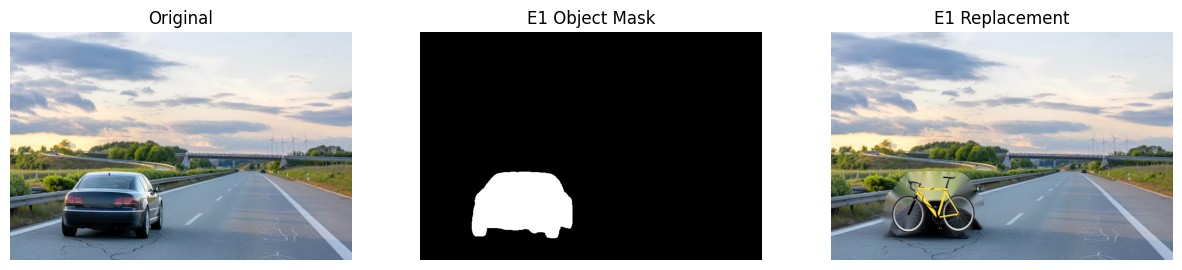

In [ ]:
plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)

plt.imshow(
    cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("Original")
plt.axis("off")


plt.subplot(1, 3, 2)

plt.imshow(
    mask,
    cmap="gray"
)

plt.title("E1 Object Mask")
plt.axis("off")


plt.subplot(1, 3, 3)

plt.imshow(
    cv2.cvtColor(
        output,
        cv2.COLOR_BGR2RGB
    )
)

plt.title("E1 Replacement")
plt.axis("off")

plt.show()

In [ ]:
def benchmark_e1(
    benchmark_cases,
    iterations=10,
    warmup=3,
    save_path="benchmarks/e1_benchmark.csv"
):

    os.makedirs(
        os.path.dirname(save_path),
        exist_ok=True
    )

    results = []

    print("=" * 70)
    print("E1 CPU BENCHMARK")
    print("=" * 70)

    for case in benchmark_cases:

        image_path = case["image"]
        instruction = case["instruction"]
        operation = case["operation"]

        image = cv2.imread(
            image_path
        )

        if image is None:
            print(
                f"Skipping: {image_path}"
            )
            continue

        height, width = image.shape[:2]

        print(
            f"\nImage: "
            f"{os.path.basename(image_path)}"
        )

        print(
            f"Resolution: "
            f"{width} x {height}"
        )

        print(
            f"Operation: {operation}"
        )

        # -----------------------------
        # Pipeline
        # -----------------------------
        if operation == "remove":

            pipeline = lambda: e1_remove(
                image,
                instruction
            )

        elif operation == "replace":

            pipeline = lambda: e1_replace(
                image,
                instruction
            )

        else:

            raise ValueError(
                f"Unknown operation: "
                f"{operation}"
            )

        # -----------------------------
        # Warmup
        # -----------------------------
        for _ in range(warmup):
            pipeline()

        # -----------------------------
        # Benchmark
        # -----------------------------
        total_times = []

        for _ in range(iterations):

            start = time.perf_counter()

            pipeline()

            elapsed = (
                time.perf_counter()
                - start
            )

            total_times.append(
                elapsed
            )

        # -----------------------------
        # Statistics
        # -----------------------------
        mean_time = np.mean(
            total_times
        )

        median_time = np.median(
            total_times
        )

        std_time = np.std(
            total_times
        )

        min_time = np.min(
            total_times
        )

        max_time = np.max(
            total_times
        )

        results.append({

            "image":
                os.path.basename(
                    image_path
                ),

            "width":
                width,

            "height":
                height,

            "resolution":
                f"{width}x{height}",

            "operation":
                operation,

            "instruction":
                instruction,

            "iterations":
                iterations,

            "mean_latency_sec":
                float(mean_time),

            "median_latency_sec":
                float(median_time),

            "std_latency_sec":
                float(std_time),

            "min_latency_sec":
                float(min_time),

            "max_latency_sec":
                float(max_time),

            "mean_latency_ms":
                float(
                    mean_time * 1000
                ),

            "yolo_size_MB":
                os.path.getsize(
                    YOLO_MODEL_NAME
                ) / (1024**2),

            "mobile_sam_size_MB":
                mobile_sam_size_mb,

            "total_model_size_MB":
                (
                    os.path.getsize(
                        YOLO_MODEL_NAME
                    ) / (1024**2)
                    +
                    mobile_sam_size_mb
                ),

            "yolo_parameters_M":
                sum(
                    p.numel()
                    for p in yolo_model.model.parameters()
                ) / 1e6,

            "mobile_sam_parameters_M":
                mobile_sam_params / 1e6,

            "total_parameters_M":
                (
                    sum(
                        p.numel()
                        for p in yolo_model.model.parameters()
                    )
                    +
                    mobile_sam_params
                ) / 1e6
        })

        print(
            f"Mean latency: "
            f"{mean_time * 1000:.2f} ms"
        )

    benchmark_df = pd.DataFrame(
        results
    )

    benchmark_df.to_csv(
        save_path,
        index=False
    )

    print("\n" + "=" * 70)

    print(
        f"Saved to: {save_path}"
    )

    print("=" * 70)

    return benchmark_df

In [ ]:
benchmark_cases = [
    {
        "image": BASE_DIR + "car_2.jpg",
        "instruction": "Remove the car",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "park_2.jpg",
        "instruction": "Remove the person",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "road_2.jpg",
        "instruction": "Remove the bicycle",
        "operation": "remove"
    },
    {
        "image": BASE_DIR + "car.jpg",
        "instruction": "Replace the car with a bicycle",
        "operation": "replace"
    }
]

In [ ]:
e1_benchmark = benchmark_e1(
    benchmark_cases,
    iterations=10,
    warmup=3,
    save_path=BENCHMARK_DIR + "e1_benchmark.csv"
)

e1_benchmark

E1 CPU BENCHMARK

Image: car_2.jpg
Resolution: 740 x 493
Operation: remove
Mean latency: 4317.51 ms

Image: park_2.jpg
Resolution: 612 x 459
Operation: remove
Mean latency: 4381.05 ms

Image: road_2.jpg
Resolution: 640 x 640
Operation: remove
Mean latency: 4596.18 ms

Image: car.jpg
Resolution: 740 x 493
Operation: replace
Mean latency: 4406.12 ms

Saved to: /content/drive/MyDrive/inter_IIT/Task_2/benchmarks/e1_benchmark.csv


,image,width,height,resolution,operation,instruction,iterations,mean_latency_sec,median_latency_sec,std_latency_sec,min_latency_sec,max_latency_sec,mean_latency_ms,yolo_size_MB,mobile_sam_size_MB,total_model_size_MB,yolo_parameters_M,mobile_sam_parameters_M,total_parameters_M
0,car_2.jpg,740,493,740x493,remove,Remove the car,10,4.317513,4.181440,0.503211,3.835556,5.349268,4317.513199,6.246372,38.841463,45.087835,3.1572,10.130092,13.287292
1,park_2.jpg,612,459,612x459,remove,Remove the person,10,4.381049,4.135202,0.494378,3.928003,5.357668,4381.048689,6.246372,38.841463,45.087835,3.1572,10.130092,13.287292
2,road_2.jpg,640,640,640x640,remove,Remove the bicycle,10,4.596184,4.174351,0.865046,3.992938,6.909305,4596.183525,6.246372,38.841463,45.087835,3.1572,10.130092,13.287292
3,car.jpg,740,493,740x493,replace,Replace the car with a bicycle,10,4.406118,4.134905,0.501744,3.934831,5.246616,4406.118275,6.246372,38.841463,45.087835,3.1572,10.130092,13.287292


In [ ]:
e0_benchmark = pd.read_csv(
    BENCHMARK_DIR + "e0_benchmark.csv"
)

e1_benchmark = pd.read_csv(
    BENCHMARK_DIR + "e1_benchmark.csv"
)

In [ ]:
e0_benchmark.columns

Index(['image', 'width', 'height', 'resolution', 'operation', 'instruction',
       'iterations', 'mean_latency_sec', 'median_latency_sec',
       'std_latency_sec', 'min_latency_sec', 'max_latency_sec',
       'mean_latency_ms', 'model_size_MB', 'parameters_M'],
      dtype='object')

In [ ]:
e1_benchmark.columns

Index(['image', 'width', 'height', 'resolution', 'operation', 'instruction',
       'iterations', 'mean_latency_sec', 'median_latency_sec',
       'std_latency_sec', 'min_latency_sec', 'max_latency_sec',
       'mean_latency_ms', 'yolo_size_MB', 'mobile_sam_size_MB',
       'total_model_size_MB', 'yolo_parameters_M', 'mobile_sam_parameters_M',
       'total_parameters_M'],
      dtype='object')

In [ ]:
comparison = pd.merge(
    e0_benchmark[
        e0_benchmark["operation"] == "remove"
    ],
    e1_benchmark[
        e1_benchmark["operation"] == "remove"
    ],
    on=[
        "image",
        "width",
        "height",
        "instruction"
    ],
    suffixes=(
        "_E0",
        "_E1"
    )
)

comparison[
    [
        "image",
        "resolution_E0",
        "mean_latency_ms_E0",
        "mean_latency_ms_E1",
        "model_size_MB",
        "total_model_size_MB"
    ]
]

,image,resolution_E0,mean_latency_ms_E0,mean_latency_ms_E1,model_size_MB,total_model_size_MB
0,car_2.jpg,740x493,349.770632,4317.513199,6.246372,45.087835
1,park_2.jpg,612x459,280.552823,4381.048689,6.246372,45.087835
2,road_2.jpg,640x640,330.473115,4596.183525,6.246372,45.087835
